# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer: Dataset title - Amazon Top 50 Best Selling Books 2009-2019. Creator - Sooter Saalu. Direct URL: https://www.kaggle.com/datasets/sootersaalu/amazon-top-50-bestselling-books-2009-2019 

**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer: One row represents one book that has been on Amazon's Top 50 bestselling boooks from 2009-2019. The dataset contains 550 books and the data was categorized into fiction and non-fiction using Goodreads. The population/location and the way the observations were collected are undocumented. There are also some price values at 0, it is undocumented whether a zero means an actual price or a missing value. For this lab we will be considering 0 to still be a price. 


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: I compared my dataset with the list of examples above to make sure I didn't reuse anything, and I made sure to not reuse my cat dataset from my earlier labs. 


## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
books_df = pd.read_csv("data/bestsellers_with_categories.csv")

In [3]:
# Display the first five rows.
books_df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [4]:
# Display the last five rows.
books_df.tail()

,Name,Author,User Rating,Reviews,Price,Year,Genre
545,Wrecking Ball (Diary of a Wimpy Kid Book 14),Jeff Kinney,4.9,9413,8,2019,Fiction
546,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2016,Non Fiction
547,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2017,Non Fiction
548,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2018,Non Fiction
549,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2019,Non Fiction


In [5]:
# Display the DataFrame shape.
books_df.shape

(550, 7)

In [6]:
# Display .info().
books_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    object 
 1   Author       550 non-null    object 
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 30.2+ KB


In [7]:
# Display missing-value counts for every feature.
books_df.isna().sum()

Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| Name | Name of the book | categorical identifier | object | 0 |
| Author | Author of the book | categorical | object | 0 |
| User Rating | Amazon user rating, 0-5 scale | quantitative | float64 | 0 |
| Reviews | Number of written reviews on Amazon | quantitative | int64 | 0 |
| Price | Book price | quantitative | int64 | 0 |
| Year | The year the book was ranked on best seller | quantitative (categorical if grouped) | int64 | 0 |
| Genre | Fiction/non-fiction | categorical | object | 0 |


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer: I will analyze Genre as my categorical feature and I will analyze user rating, reviews and price as my quantitative features. They are appropriate for distribution comparison because their data can be compared across a range of values, not just as a single summary. 


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of user rating differ among genres throughout the dataset's time period?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict the non-fiction genre will have a higher center than the fiction genre. I believe a lot of people rate fiction books a lot harsher than then they do non-fiction. Fiction books ratings can be biased based on each reader's personal opinion, while non-fiction books I believe wouldn't be too harsh on ratings since they are fact based. 


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use user rating, genre and year. I will be filtering the dataset by year and then genre. From there I'll calculate the center and spread of the user ratings. Each observation represents a book. 


In [8]:
# Prepare this question's analysis DataFrame and preview the selected features.
books_rating_df = books_df.loc[books_df["Year"].isin([2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019])].copy().sort_values(by="Year")
books_rating_df.shape

(550, 7)

In [9]:
# Display the number of usable observations in each group.
books_rating_df["Year"].value_counts()

Year
2009    50
2010    50
2011    50
2012    50
2013    50
2014    50
2015    50
2016    50
2017    50
2018    50
2019    50
Name: count, dtype: int64

In [10]:
books_rating_df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
25,Arguing with Idiots: How to Stop Small Minds a...,Glenn Beck,4.6,798,5,2009,Non Fiction
513,"Twilight (The Twilight Saga, Book 1)",Stephenie Meyer,4.7,11676,9,2009,Fiction
512,True Compass: A Memoir,Edward M. Kennedy,4.5,438,15,2009,Non Fiction
520,Under the Dome: A Novel,Stephen King,4.3,6740,20,2009,Fiction
524,Watchmen,Alan Moore,4.8,3829,42,2009,Fiction


### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


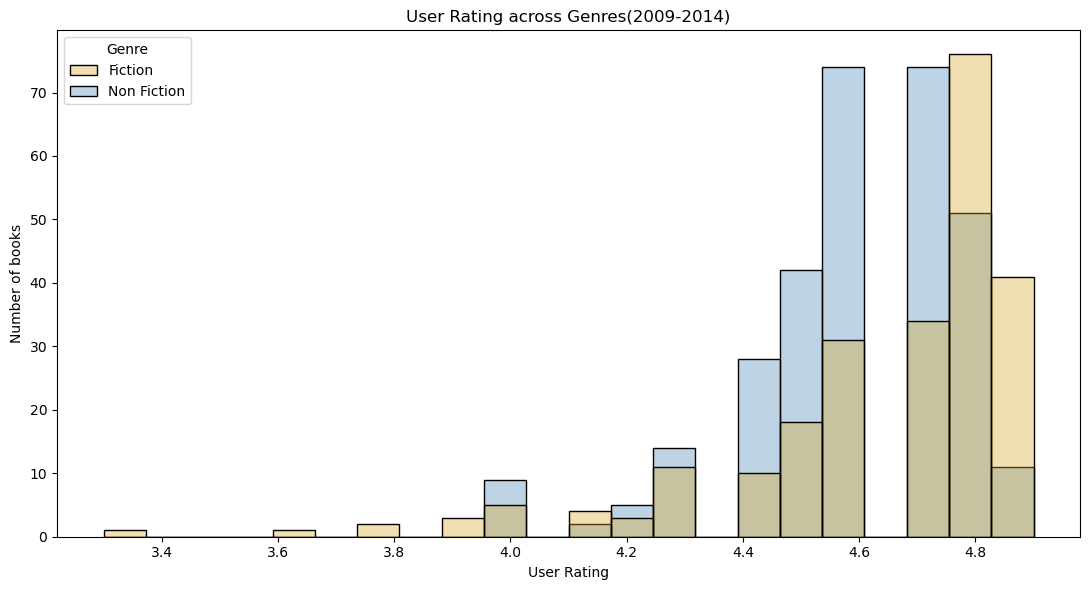

In [11]:
# Create and label the histogram comparison.
plt.figure(figsize=(11, 6))
sns.histplot(data=books_rating_df, x="User Rating", hue="Genre",
             hue_order=['Fiction', 'Non Fiction'], palette=["goldenrod", "steelblue"], fill=True, alpha=0.35)
plt.title("User Rating across Genres(2009-2014)")
plt.xlabel("User Rating")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Fiction - max: 4.9, min: 3.3; Non-fiction - max:4.9, min: 4.0. Both genres seem to be pretty close in values and overlap in quite a few ratings. Both genres are left skewed, but fiction books appear to have more outliers. Fiction books appear to have lower ratings than non-fiction books.


In [12]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
books_rating_df.groupby("Genre")["User Rating"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Genre,,,,,,,,
Fiction,240.0,4.65,0.27,3.3,4.6,4.7,4.8,4.9
Non Fiction,310.0,4.60,0.19,4.0,4.5,4.6,4.7,4.9


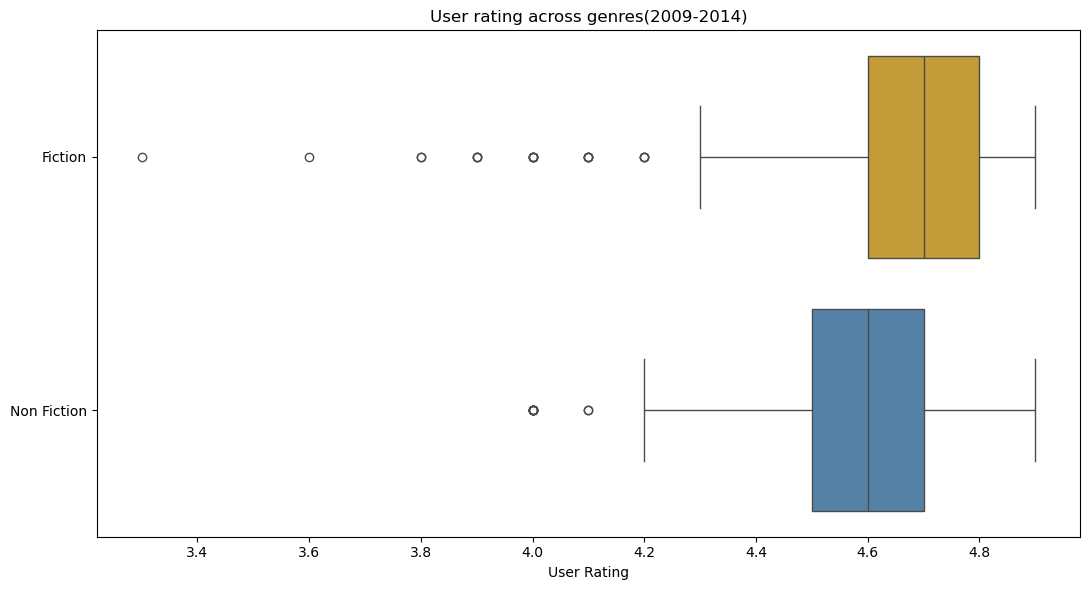

In [13]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, 6))
sns.boxplot(data=books_rating_df, x="User Rating", y="Genre",
             order=['Fiction', 'Non Fiction'], hue="Genre", hue_order=['Fiction', 'Non Fiction'],
             palette=["goldenrod", "steelblue"], legend=False)
plt.title("User rating across genres(2009-2014)")
plt.xlabel("User Rating")
plt.ylabel("")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: My estimated min and max vakues were equal, but I did predict non-fiction books to have a higher center. The genres appear similar in shape, but fiction books have a lot more lower user rating outliers.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [14]:
# Perform a targeted check against original records or the declared group definitions.
books_rating_df.groupby("Genre")["User Rating"].agg(["min", "max", "count"])

,min,max,count
Genre,,,
Fiction,3.3,4.9,240
Non Fiction,4.0,4.9,310


In [15]:
books_rating_df.nlargest(5, "User Rating")[["Name", "Author", "User Rating", "Genre"]]

,Name,Author,User Rating,Genre
187,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,4.9,Non Fiction
146,"Goodnight, Goodnight Construction Site (Hardco...",Sherri Duskey Rinker,4.9,Fiction
245,"Oh, the Places You'll Go!",Dr. Seuss,4.9,Fiction
188,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,4.9,Non Fiction
420,The Legend of Zelda: Hyrule Historia,Patrick Thorpe,4.9,Fiction


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: Any negative values would make me suspicious because user ratings don't typically fall below 0, alos, if these are amazon's top 50 bestselling books, there wouldn't be as many negative ratings. My check established the maximum values and the genres they belong to. 


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Overall, the distribution of user rating doesn't differ too much among genres throughout the dataset's time period. Their shapes in the box plot were retty similar and overlapped. Both fiction and non-fiction genres had the user rating 4.9 as their maximum and their median were only 0.1 off. Fiction books did have more outliers and their minimum value was 3.3, compared to the non-fictions's minimum value at 4.0. 


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: Avoid concluding that the user rating between fiction and non-fiction books will always be similar thorughout the years. As the time passes, people's interests are always changing and that can lead to an increase or decrease in either genre's user rating. 


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of price differ among genres throughout the dataset's time period?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict the non-fiction genre will have a higher center than the fiction genre. I believe selling non-fiction books cost more due to the amount they pay to print the books. Seeing that non-fiction books have more graphs and charts, compared to fiction books that might not have any at all. Those extra images might cost more. Their shapes might not overlap as much, and the fiction books might have some more higher priced outliers due to some popular series they might have. 


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use price, genre and year. I will be filtering the dataset by year and then genre. From there I'll calculate the center and spread of the prices. Each observation represents a book.


In [16]:
# Prepare this question's analysis DataFrame and preview the selected features.
books_prices_df = books_df.loc[books_df["Year"].isin([2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019])].copy().sort_values(by="Year")
books_prices_df.shape

(550, 7)

In [17]:
# Display the number of usable observations in each group.
books_prices_df["Year"].value_counts()

Year
2009    50
2010    50
2011    50
2012    50
2013    50
2014    50
2015    50
2016    50
2017    50
2018    50
2019    50
Name: count, dtype: int64

In [18]:
books_prices_df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
25,Arguing with Idiots: How to Stop Small Minds a...,Glenn Beck,4.6,798,5,2009,Non Fiction
513,"Twilight (The Twilight Saga, Book 1)",Stephenie Meyer,4.7,11676,9,2009,Fiction
512,True Compass: A Memoir,Edward M. Kennedy,4.5,438,15,2009,Non Fiction
520,Under the Dome: A Novel,Stephen King,4.3,6740,20,2009,Fiction
524,Watchmen,Alan Moore,4.8,3829,42,2009,Fiction


### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


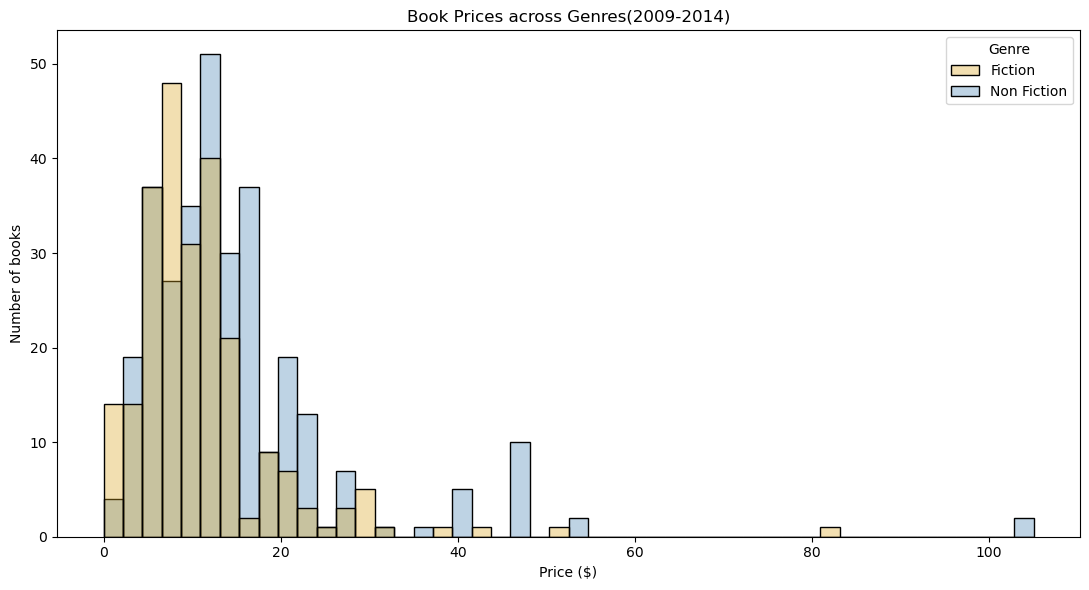

In [19]:
# Create and label the histogram comparison.
plt.figure(figsize=(11, 6))
sns.histplot(data=books_prices_df, x="Price", hue="Genre",
             hue_order=['Fiction', 'Non Fiction'], palette=["goldenrod", "steelblue"], fill=True, alpha=0.35)
plt.title("Book Prices across Genres(2009-2014)")
plt.xlabel("Price ($)")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Fiction - max: 82, min: 5; Non-fiction - max: 110, min: 10. Both genres seem to be pretty close in values and overlap in quite a few prices. Both genres are right skewed and both have similar outliers at higher prices.


In [20]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
books_prices_df.groupby("Genre")["Price"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Genre,,,,,,,,
Fiction,240.0,10.85,8.57,0.0,6.0,9.0,13.0,82.0
Non Fiction,310.0,14.84,12.04,0.0,8.0,12.0,17.0,105.0


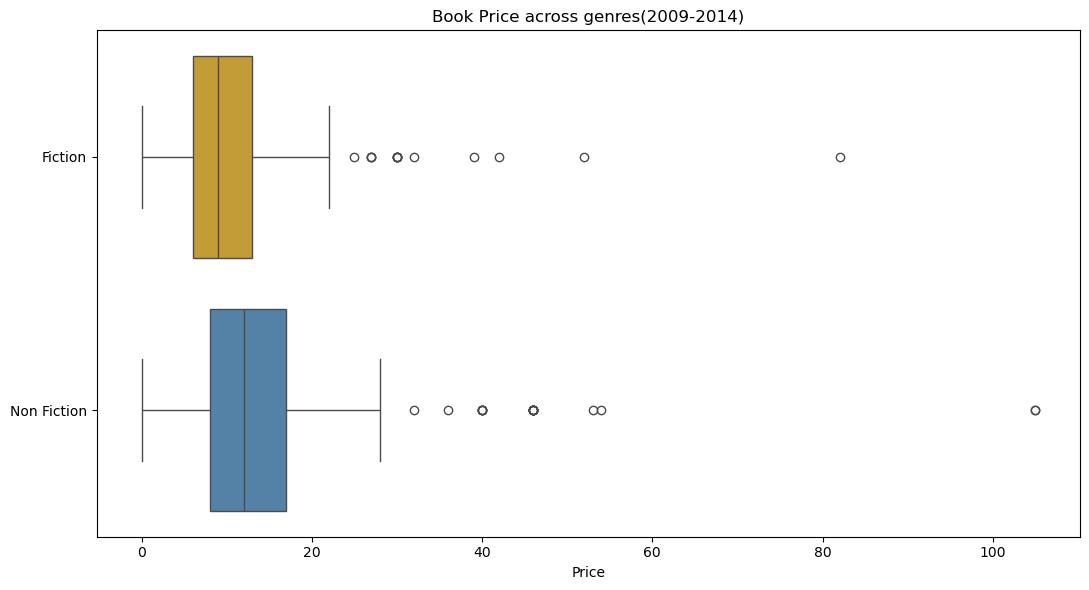

In [21]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, 6))
sns.boxplot(data=books_prices_df, x="Price", y="Genre",
             order=['Fiction', 'Non Fiction'], hue="Genre", hue_order=['Fiction', 'Non Fiction'],
             palette=["goldenrod", "steelblue"], legend=False)
plt.title("Book Price across genres(2009-2014)")
plt.xlabel("Price")
plt.ylabel("")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The min values I estimated for both genres were off by 5, I did forget that there were zeros in this grouping and we decided to keep them in as prices. The fiction max value I estimated ws the same and the non fiction max value I estimated was off by 5. Both genres look similar but the non-fiction genre had a higher center and 3rd quartile range. Both genres had a lot of outliers but non-fiction had the highest. 


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [22]:
# Perform a targeted check against original records or the declared group definitions.
books_prices_df.groupby("Genre")["Price"].agg(["min", "max", "count"])

,min,max,count
Genre,,,
Fiction,0,82,240
Non Fiction,0,105,310


In [23]:
books_prices_df.nlargest(5, "Price")[["Name", "Author", "Price", "Genre"]]

,Name,Author,Price,Genre
69,Diagnostic and Statistical Manual of Mental Di...,American Psychiatric Association,105,Non Fiction
70,Diagnostic and Statistical Manual of Mental Di...,American Psychiatric Association,105,Non Fiction
473,The Twilight Saga Collection,Stephenie Meyer,82,Fiction
151,Hamilton: The Revolution,Lin-Manuel Miranda,54,Non Fiction
346,The Book of Basketball: The NBA According to T...,Bill Simmons,53,Non Fiction


In [24]:
books_prices_df.nsmallest(5, "Price")[["Name", "Author", "Price", "Genre"]]

,Name,Author,Price,Genre
461,The Short Second Life of Bree Tanner: An Eclip...,Stephenie Meyer,0,Fiction
42,"Cabin Fever (Diary of a Wimpy Kid, Book 6)",Jeff Kinney,0,Fiction
71,"Diary of a Wimpy Kid: Hard Luck, Book 8",Jeff Kinney,0,Fiction
505,To Kill a Mockingbird,Harper Lee,0,Fiction
506,To Kill a Mockingbird,Harper Lee,0,Fiction


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: Any negative values would make me suspicious because prices don't fall below 0. There are quite a few more zeros than I anticipated, so that makes me susipicious on what the dataset's creator meant by the zeros in this dataset. I decided to keep them as zeros for the price, maybe next time I'll factor the zeros as missing values. My check did establish the maximum values and the genres they belong to. 


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: The distribution of price among genres throughout the dataset's time period doesn't differ as much. There's been a pretty similar price for both genres. The non-fiction genre does have a higher center and higher priced outliers, but they overlap a lot between the 0-30 dollar price range.  


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: Avoid concluding that the prices between fiction and non-fiction books will always be similar thorughout the years. As the time passes, people's interests are always changing and that can lead to an increase or decrease in either genre's prices. 


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer: Does the distribution of reviews differ among genre based on the author?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I think the authors of fiction books will have a higher center than the authors of non-fiction books. Fiction books might be more suscestible to opinion based reviews and that might affect the amount of reviews. Non-fiction books might not have that many opinion-based reviews since the books are fact-based. There might be an overlap between both genres but I believe fiction books will have a larger spread.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use reviews, genre and author. I will be filtering the dataset by authors and then genre. From there I'll calculate the center and spread of the reviews. Each observation represents a book.


In [25]:
# Prepare this question's analysis DataFrame and preview the selected features.
books_reviews_df = books_df.loc[books_df["Author"].notna()].copy().sort_values(by="Reviews")
books_reviews_df.shape

(550, 7)

In [26]:
# Display the number of usable observations in each group.
books_reviews_df["Author"].value_counts()

Author
Jeff Kinney                           12
Rick Riordan                          11
Gary Chapman                          11
Suzanne Collins                       11
American Psychological Association    10
                                      ..
Alex Michaelides                       1
Margaret Atwood                        1
Paulo Coelho                           1
Andy Weir                              1
Delia Owens                            1
Name: count, Length: 248, dtype: int64

In [27]:
books_reviews_df.count()

Name           550
Author         550
User Rating    550
Reviews        550
Price          550
Year           550
Genre          550
dtype: int64

In [28]:
books_reviews_df.head(10)

,Name,Author,User Rating,Reviews,Price,Year,Genre
78,Divine Soul Mind Body Healing and Transmission...,Zhi Gang Sha,4.6,37,6,2009,Non Fiction
300,Soul Healing Miracles: Ancient and New Sacred ...,Zhi Gang Sha,4.6,220,17,2013,Non Fiction
121,George Washington's Sacred Fire,Peter A. Lillback,4.5,408,20,2010,Non Fiction
512,True Compass: A Memoir,Edward M. Kennedy,4.5,438,15,2009,Non Fiction
359,The Daily Show with Jon Stewart Presents Earth...,Jon Stewart,4.4,440,11,2010,Non Fiction
11,A Patriot's History of the United States: From...,Larry Schweikart,4.6,460,2,2010,Non Fiction
39,"Broke: The Plan to Restore Our Trust, Truth an...",Glenn Beck,4.5,471,8,2010,Non Fiction
27,"Autobiography of Mark Twain, Vol. 1",Mark Twain,4.2,491,14,2010,Non Fiction
264,Percy Jackson and the Olympians Paperback Boxe...,Rick Riordan,4.8,548,2,2010,Fiction
31,"Barefoot Contessa, How Easy Is That?: Fabulous...",Ina Garten,4.7,615,21,2010,Non Fiction


### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


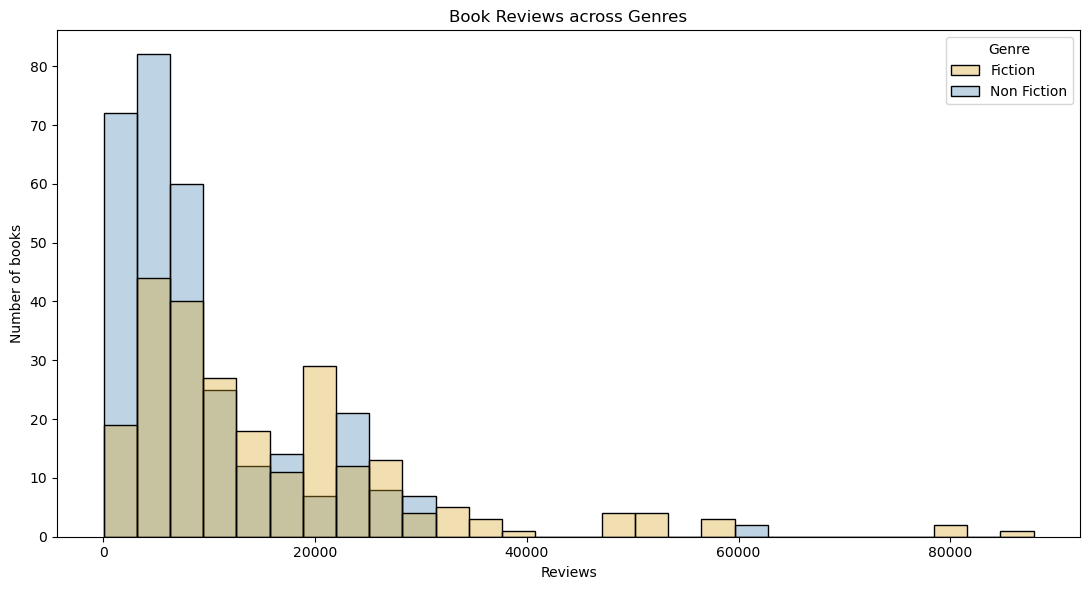

In [29]:
# Create and label the histogram comparison.
plt.figure(figsize=(11, 6))
sns.histplot(data=books_reviews_df, x="Reviews", hue="Genre",
             hue_order=['Fiction', 'Non Fiction'], palette=["goldenrod", "steelblue"], fill=True, alpha=0.35)
plt.title("Book Reviews across Genres")
plt.xlabel("Reviews")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Fiction - max: 85000, min: 0; Non-fiction - max: 65000, min: 0. A lot more non-fiction books have lower review numbers, but they also overlap in quite a few reviews. Both right skewed but fictions books have more higher review number outliers. 


In [30]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
books_reviews_df.groupby("Genre")["Reviews"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Genre,,,,,,,,
Fiction,240.0,15683.79,13984.12,548.0,6162.5,10922.0,21834.00,87841.0
Non Fiction,310.0,9065.15,8606.74,37.0,3235.0,6346.0,11124.25,61133.0


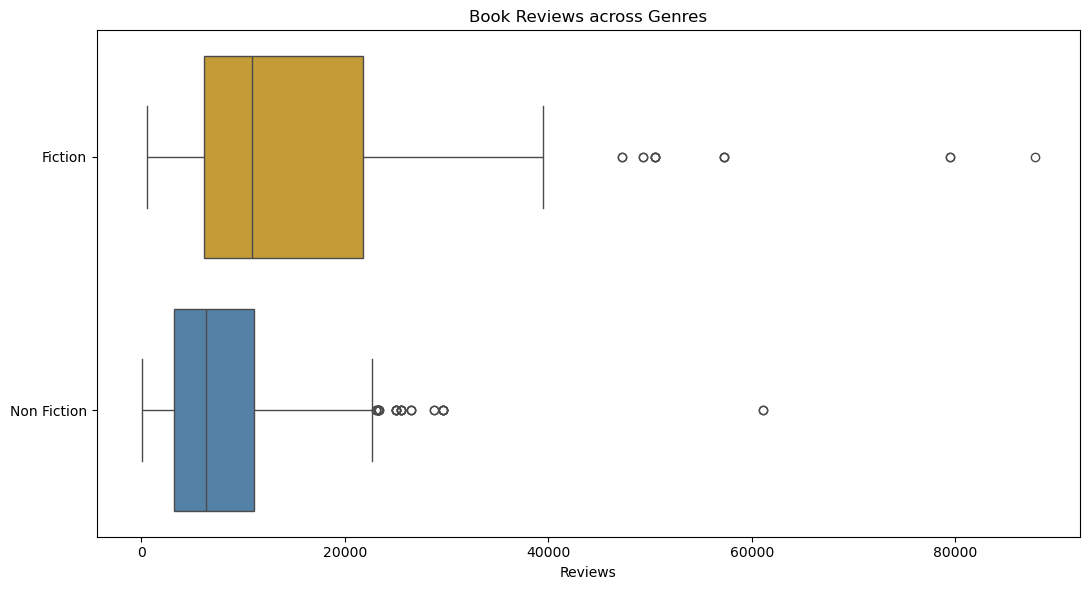

In [31]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, 6))
sns.boxplot(data=books_reviews_df, x="Reviews", y="Genre",
             order=['Fiction', 'Non Fiction'], hue="Genre", hue_order=['Fiction', 'Non Fiction'],
             palette=["goldenrod", "steelblue"], legend=False)
plt.title("Book Reviews across Genres")
plt.xlabel("Reviews")
plt.ylabel("")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The min values I estimated for both genres were off, the non-fiction genre was off by 37 reviews and the fiction genre was off by 548 reveiws. My max values weren't pff by much. The fitcion is a lot bigger in shape and a lot more spread out. They also have the most outliers and the highest one.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [32]:
# Perform a targeted check against original records or the declared group definitions.
books_reviews_df.groupby("Genre")["Reviews"].agg(["min", "max", "count"])

,min,max,count
Genre,,,
Fiction,548,87841,240
Non Fiction,37,61133,310


In [33]:
books_reviews_df.nlargest(10, "Reviews")[["Name", "Author", "Reviews", "Genre"]]

,Name,Author,Reviews,Genre
534,Where the Crawdads Sing,Delia Owens,87841,Fiction
383,The Girl on the Train,Paula Hawkins,79446,Fiction
382,The Girl on the Train,Paula Hawkins,79446,Fiction
32,Becoming,Michelle Obama,61133,Non Fiction
33,Becoming,Michelle Obama,61133,Non Fiction
135,Gone Girl,Gillian Flynn,57271,Fiction
137,Gone Girl,Gillian Flynn,57271,Fiction
136,Gone Girl,Gillian Flynn,57271,Fiction
368,The Fault in Our Stars,John Green,50482,Fiction
367,The Fault in Our Stars,John Green,50482,Fiction


In [34]:
books_reviews_df.nsmallest(10, "Reviews")[["Name", "Author", "Reviews", "Genre"]]

,Name,Author,Reviews,Genre
78,Divine Soul Mind Body Healing and Transmission...,Zhi Gang Sha,37,Non Fiction
300,Soul Healing Miracles: Ancient and New Sacred ...,Zhi Gang Sha,220,Non Fiction
121,George Washington's Sacred Fire,Peter A. Lillback,408,Non Fiction
512,True Compass: A Memoir,Edward M. Kennedy,438,Non Fiction
359,The Daily Show with Jon Stewart Presents Earth...,Jon Stewart,440,Non Fiction
11,A Patriot's History of the United States: From...,Larry Schweikart,460,Non Fiction
39,"Broke: The Plan to Restore Our Trust, Truth an...",Glenn Beck,471,Non Fiction
27,"Autobiography of Mark Twain, Vol. 1",Mark Twain,491,Non Fiction
264,Percy Jackson and the Olympians Paperback Boxe...,Rick Riordan,548,Fiction
31,"Barefoot Contessa, How Easy Is That?: Fabulous...",Ina Garten,615,Non Fiction


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: Negative reviews would make me suspicious, but so would 0 values. From the histogram and box plot I assumed the minimum values would be 0, but I was wrong. Being Amazon's top 50 bestselling  books, it wouldn't make sense for them to not havy any reviews. My checks established the maximum and minimum values and the genre they belong to.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: The distribution of reviews does differ among genre, fiction books tend to have a lot more reviews than non-fiction books. There was some overlap in their shapes, but, the fiction genre had a bigger shape and was more spread out than the non-fiction genre. The review counts and genre do sometimes reflet on the author, some of the higher reviewed books come from the authors who were on Amazon's top 50 bestselling books more than once with the same book.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: Avoid concluding that the reviews for fiction books will always be higher than the reviews for non-fiction books. As the time passes, people's interests are always changing and that can lead to an increase or decrease in either genre's reviews.  


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I did not use AI. 


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
